# We only know outcomes for the people we approved

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/data-quality-governance/selective-labels/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=data-quality-governance/selective-labels/demo.ipynb)

Every credit model is trained and judged on the loans someone once approved. Those officers used an interview read
the data never recorded, and held group B to a higher bar. This notebook measures what that label set does to a
model trained on it, to the dashboard that evaluates it, to a fairness audit, and to the standard fixes.

1. The engine
2. The label set is a selected sample
3. Two models, scored on the truth
4. Five estimators, one verdict each
5. How big a random-explore slice must be
6. Control: when selection runs on recorded data
7. The chart
8. Try your own

## 1. The engine

Extracted from `selective.py` at build time. `draw` makes one history period and the officers' decisions; `fit`
trains gradient boosting on bureau score and group (never the interview read); `evaluate` scores a model on a
history period five ways. `study` runs the same three seeds as `evidence.py` (about 10 seconds per world), so the
numbers match `evidence.txt` exactly.

In [1]:
from __future__ import annotations

import warnings
from typing import Dict, List, Optional

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier

warnings.filterwarnings("ignore", category=RuntimeWarning)

SEEDS = [200, 201, 202]


N = 40_000  # applicants per history period (one to train on, one to evaluate on)


APPROVE = 0.40  # capacity: the share approved, then and now


EXPLORE = [0.01, 0.02, 0.05, 0.10]  # share of applicants approved at random in the evaluation period


Z = 1.96


WORLD: Dict[str, float] = {
    "share_b": 0.30,
    "sel_u": 1.0,  # how much officers leaned on the unrecorded read (0 = recorded data only)
    "bar_b": 0.6,  # the extra bar group B had to clear (sd)
    "officer_noise": 0.5,
    "noise": 0.8,
}


CONTROL: Dict[str, float] = dict(WORLD, sel_u=0.0)


def draw(n: int, rng: np.random.Generator, w: Optional[Dict[str, float]] = None) -> Dict[str, np.ndarray]:
    """One history period: applicants, the true outcome, and the officers' decision (label observed iff approved)."""
    w = w or WORLD
    g = (rng.random(n) < w["share_b"]).astype(int)
    x = rng.normal(0, 1, n)
    u = rng.normal(0, 1, n)
    y = (0.8 * x + 0.8 * u + rng.normal(0, w["noise"], n) > -0.4).astype(int)  # 1 = repays
    s = x + w["sel_u"] * u - w["bar_b"] * g + rng.normal(0, w["officer_noise"], n)
    approved = s >= np.quantile(s, 1 - APPROVE)
    return {"x": x, "u": u, "g": g, "y": y, "approved": approved}


def features(d: Dict[str, np.ndarray]) -> np.ndarray:
    return np.column_stack([d["x"], d["g"]])


def fit(d: Dict[str, np.ndarray], mask: Optional[np.ndarray] = None) -> HistGradientBoostingClassifier:
    m = np.ones(len(d["y"]), bool) if mask is None else mask
    return HistGradientBoostingClassifier(random_state=0).fit(features(d)[m], d["y"][m])


def decide(model: HistGradientBoostingClassifier, d: Dict[str, np.ndarray]) -> np.ndarray:
    p = model.predict_proba(features(d))[:, 1]
    return p >= np.quantile(p, 1 - APPROVE)


def propensity(d: Dict[str, np.ndarray]) -> np.ndarray:
    """P(past approval | x, g), fitted on the recorded features: all an analyst has."""
    clf = HistGradientBoostingClassifier(random_state=0).fit(features(d), d["approved"].astype(int))
    return np.clip(clf.predict_proba(features(d))[:, 1], 0.02, 1.0)


def metrics(y: np.ndarray, a: np.ndarray, g: np.ndarray, wt: Optional[np.ndarray] = None) -> Dict[str, float]:
    """Repay rate among the model's approvals, and true positive rate (good payers approved) per group."""
    wt = np.ones(len(y)) if wt is None else wt

    def rate(num: np.ndarray, den: np.ndarray) -> float:
        s = float((wt * den).sum())
        return float((wt * num * den).sum() / s) if s > 0 else float("nan")

    out = {"repay": rate(y, a)}
    for k, name in ((0, "A"), (1, "B")):
        out[f"tpr_{name}"] = rate(a, (y == 1) & (g == k))
    out["tpr_gap"] = out["tpr_A"] - out["tpr_B"]
    return out


def evaluate(
    model: HistGradientBoostingClassifier, d: Dict[str, np.ndarray], seed: int
) -> Dict[str, Dict[str, float]]:
    """The model's metrics on a history period, four ways plus the truth."""
    a = decide(model, d)
    y, g, lab = d["y"], d["g"], d["approved"]
    out = {
        "truth": metrics(y, a, g),
        "labeled": metrics(y[lab], a[lab], g[lab]),
        "rejected_bad": metrics(np.where(lab, y, 0), a, g),
        "ipw": metrics(y[lab], a[lab], g[lab], 1 / propensity(d)[lab]),
    }
    rng = np.random.default_rng(seed + 50_000)
    order = rng.permutation(len(y))
    for e in EXPLORE:
        sl = order[: int(e * len(y))]
        m = metrics(y[sl], a[sl], g[sl])
        k = int(a[sl].sum())
        m["n_approved"] = k
        m["ci_half"] = float(Z * np.sqrt(m["repay"] * (1 - m["repay"]) / k)) if k else float("nan")
        out[f"explore_{e:g}"] = m
    return out


def one_seed(seed: int, w: Optional[Dict[str, float]] = None, n: int = N) -> Dict[str, object]:
    rng = np.random.default_rng(seed)
    train, ev = draw(n, rng, w), draw(n, rng, w)
    m_lab = fit(train, train["approved"])  # what a team can actually train
    m_full = fit(train)  # the oracle: every outcome known
    a_lab, a_full = decide(m_lab, ev), decide(m_full, ev)
    b = ev["g"] == 1
    return {
        "labeled_share": float(train["approved"].mean()),
        "hist_repay_labeled": float(train["y"][train["approved"]].mean()),
        "pop_repay": float(train["y"].mean()),
        "b_labeled_repay": float(train["y"][train["approved"] & (train["g"] == 1)].mean()),
        "a_labeled_repay": float(train["y"][train["approved"] & (train["g"] == 0)].mean()),
        "eval_lab_model": evaluate(m_lab, ev, seed),
        "eval_full_model": evaluate(m_full, ev, seed),
        "share_b_approved": {"labeled": float(a_lab[b].mean()), "oracle": float(a_full[b].mean())},
    }


def study(seeds: Optional[List[int]] = None, w: Optional[Dict[str, float]] = None) -> Dict[str, object]:
    seeds = seeds or SEEDS
    per = [one_seed(s, w) for s in seeds]

    def agg(vals) -> Dict[str, float]:
        v = np.array(vals, float)
        return {"mean": float(v.mean()), "lo": float(v.min()), "hi": float(v.max())}

    def tree(get) -> object:
        first = get(per[0])
        if isinstance(first, dict):
            return {k: tree(lambda p, k=k, get=get: get(p)[k]) for k in first}
        return agg([get(p) for p in per])

    return {"seeds": seeds, "n": N, **tree(lambda p: p)}


def parse_world(text: str) -> Dict[str, float]:
    """`key=value` overrides of WORLD (e.g. "sel_u=0, bar_b=1.0")."""
    w = dict(WORLD)
    for part in [p.strip() for p in text.split(",") if p.strip()]:
        if "=" not in part:
            raise ValueError(f"expected key=value, got {part!r}")
        k, v = [x.strip() for x in part.split("=", 1)]
        if k not in WORLD:
            raise ValueError(f"unknown setting {k!r}; known: {', '.join(WORLD)}")
        try:
            w[k] = float(v)
        except ValueError:
            raise ValueError(f"{k} needs a number, got {v!r}") from None
    if not 0 < w["share_b"] < 1:
        raise ValueError("share_b must be between 0 and 1")
    return w

In [2]:
r = study()
c = study(w=CONTROL)
pct = lambda v: f"{v['mean']:.1%} [{v['lo']:.1%}-{v['hi']:.1%}]"
pts = lambda v: f"{v['mean'] * 100:+.1f} [{v['lo'] * 100:+.1f} to {v['hi'] * 100:+.1f}]"
print(f"study done: {len(r['seeds'])} seeds, {r['n']:,} applicants per period")

study done: 3 seeds, 40,000 applicants per period


## 2. The label set is a selected sample

61% of applicants repay; 91% of the labeled rows do. Group B's labeled rows repay at 95% against A's 90%, because
only B applicants who cleared a 0.6 sd higher bar were ever approved. The higher bar reads, in the labels, as lower
risk.

In [3]:
print(f"repay rate, all applicants: {pct(r['pop_repay'])}; labeled (approved) rows: {pct(r['hist_repay_labeled'])}")
print(f"labeled repay rate by group: A {pct(r['a_labeled_repay'])}, B {pct(r['b_labeled_repay'])} (B cleared a {WORLD['bar_b']} sd higher bar)")

repay rate, all applicants: 61.3% [61.2%-61.4%]; labeled (approved) rows: 90.9% [90.9%-91.1%]
labeled repay rate by group: A 89.9% [89.8%-89.9%], B 94.7% [94.4%-95.2%] (B cleared a 0.6 sd higher bar)


## 3. Two models, scored on the truth

The oracle is trained on every outcome (only a simulation has them); the other on the labeled rows, as a team would.
The label-trained model approves 69% of group B against the oracle's 39%, and its approvals truly repay 76.4% against
82.8%. Past prejudice against B became, through the labels, a model that over-approves B.

In [4]:
print(f"{'model':<22} {'repay among approved':>22} {'share of B approved':>22} {'TPR A':>8} {'TPR B':>8}")
for key, name, sb in (("eval_full_model", "oracle (all outcomes)", "oracle"), ("eval_lab_model", "trained on labels", "labeled")):
    t = r[key]["truth"]
    print(f"{name:<22} {pct(t['repay']):>22} {pct(r['share_b_approved'][sb]):>22} {t['tpr_A']['mean']:>8.1%} {t['tpr_B']['mean']:>8.1%}")

model                    repay among approved    share of B approved    TPR A    TPR B
oracle (all outcomes)     82.8% [82.6%-83.0%]    39.3% [38.2%-40.4%]    55.1%    53.2%
trained on labels         76.4% [73.1%-78.6%]    69.0% [61.5%-74.9%]    39.8%    76.1%


## 4. Five estimators, one verdict each

The labeled rows put the label-trained model ahead, 94.3% against 93.7%, at every seed: they rank the worse model
first. Counting every rejected applicant as a default ranks correctly but reads 20 points low. IPW, with the
propensity of approval fitted on bureau score and group, reads 93% for both and calls it a tie: it cannot reweight
on a signal nobody recorded. Only a 5% random-explore slice gets both numbers right. The fairness audit is no safer:
the oracle's true TPR gap is +2.0 points, the labeled rows say -5.7.

In [5]:
EST = [("truth", "truth (all outcomes)"), ("labeled", "labeled rows only"), ("rejected_bad", "rejected = bad"),
       ("ipw", "IPW on x, group"), ("explore_0.05", "5% random explore")]
print(f"{'estimator':<22} {'oracle repay':>22} {'label-trained repay':>22} {'oracle TPR gap A-B (pts)':>28}  ranks right?")
for k, name in EST:
    o, lm = r["eval_full_model"][k], r["eval_lab_model"][k]
    right = "yes" if o["repay"]["lo"] > lm["repay"]["hi"] else "NO" if o["repay"]["hi"] < lm["repay"]["lo"] else "tie"
    print(f"{name:<22} {pct(o['repay']):>22} {pct(lm['repay']):>22} {pts(o['tpr_gap']):>28}  {right}")

estimator                        oracle repay    label-trained repay     oracle TPR gap A-B (pts)  ranks right?
truth (all outcomes)      82.8% [82.6%-83.0%]    76.4% [73.1%-78.6%]          +2.0 [+0.9 to +3.1]  yes
labeled rows only         93.7% [93.3%-93.9%]    94.3% [94.2%-94.5%]          -5.7 [-6.7 to -4.7]  NO
rejected = bad            62.5% [62.4%-62.7%]    52.7% [50.3%-55.0%]          -5.7 [-6.7 to -4.7]  yes
IPW on x, group           93.2% [92.8%-93.5%]    92.9% [92.6%-93.2%]          -0.2 [-1.5 to +1.0]  tie
5% random explore         82.9% [81.5%-84.6%]    77.1% [71.8%-80.4%]          +4.3 [+3.2 to +5.7]  yes


## 5. How big a random-explore slice must be

Approving a random share of applicants regardless of score is the one label set nobody selected. 1% gives about 160
labeled approvals and a 95% interval of +/-6.1 points; 5% gives +/-2.6; 10% gives +/-1.8. The price is the loans
approved that the score would have refused.

In [6]:
print(f"truth {r['eval_full_model']['truth']['repay']['mean']:.1%}")
for e in EXPLORE:
    v = r["eval_full_model"][f"explore_{e:g}"]
    print(f"  explore {e:>4.0%}: {v['n_approved']['mean']:>6,.0f} labeled approvals, estimate {pct(v['repay'])}, 95% CI +/- {v['ci_half']['mean'] * 100:.1f} pts")

truth 82.8%
  explore   1%:    162 labeled approvals, estimate 80.2% [77.2%-82.9%], 95% CI +/- 6.1 pts
  explore   2%:    325 labeled approvals, estimate 81.9% [81.1%-82.4%], 95% CI +/- 4.2 pts
  explore   5%:    804 labeled approvals, estimate 82.9% [81.5%-84.6%], 95% CI +/- 2.6 pts
  explore  10%:  1,623 labeled approvals, estimate 83.1% [82.5%-83.5%], 95% CI +/- 1.8 pts


## 6. Control: when selection runs on recorded data

Set `sel_u = 0`: officers used only bureau score and group. Now IPW recovers the repay rate (82.5% against 82.8%),
and training on the labeled rows costs almost nothing (82.3%). So the method is not broken; the world was. One
negative result survives: IPW's TPR for group B still reads 67.2% against a true 53.2%, because a quarter of B's
good payers had under a 2% chance of approval and almost none of them carry a label. Weighting cannot reach
people who were never approved.

In [7]:
for k, name in EST[:4]:
    o = c["eval_full_model"][k]
    print(f"{name:<22} oracle repay {pct(o['repay'])}   TPR B {pct(o['tpr_B'])}")
print(f"label-trained model, true repay {pct(c['eval_lab_model']['truth']['repay'])}; share of B approved {pct(c['share_b_approved']['labeled'])} vs oracle {pct(c['share_b_approved']['oracle'])}")

truth (all outcomes)   oracle repay 82.8% [82.6%-83.0%]   TPR B 53.2% [52.1%-54.3%]
labeled rows only      oracle repay 84.3% [84.0%-84.5%]   TPR B 93.5% [92.9%-94.6%]
rejected = bad         oracle repay 67.4% [66.9%-67.7%]   TPR B 93.5% [92.9%-94.6%]
IPW on x, group        oracle repay 82.5% [82.4%-82.7%]   TPR B 67.2% [65.0%-69.2%]
label-trained model, true repay 82.3% [82.0%-82.4%]; share of B approved 39.3% [35.6%-41.6%] vs oracle 39.3% [38.2%-40.4%]


## 7. The chart

The full figure, with the decision boundary drawn, is `audit.png` (built by `make_chart.py`). Here, the five
estimators side by side.

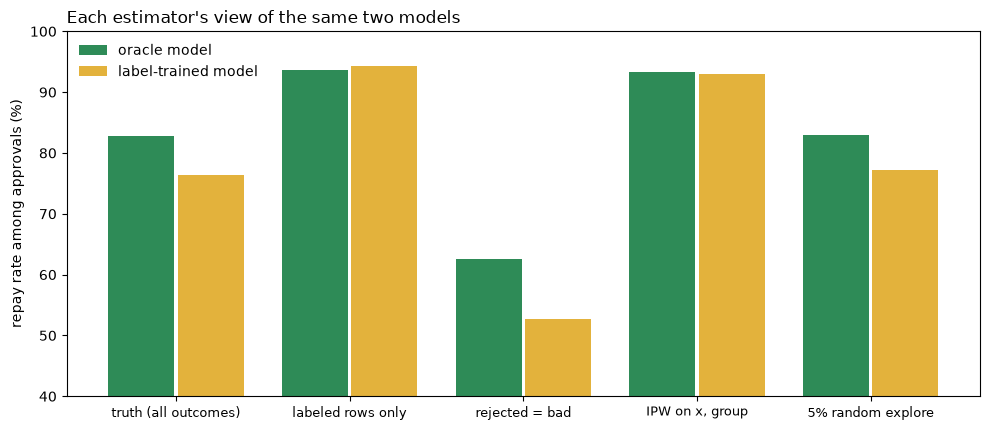

In [8]:
xs = np.arange(len(EST))
o, lm = r["eval_full_model"], r["eval_lab_model"]
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.bar(xs - 0.2, [o[k]["repay"]["mean"] * 100 for k, _ in EST], 0.38, color="#2e8b57", label="oracle model")
ax.bar(xs + 0.2, [lm[k]["repay"]["mean"] * 100 for k, _ in EST], 0.38, color="#e3b23c", label="label-trained model")
ax.set_xticks(xs)
ax.set_xticklabels([n for _, n in EST], fontsize=9)
ax.set_ylim(40, 100)
ax.set_ylabel("repay rate among approvals (%)")
ax.set_title("Each estimator's view of the same two models", loc="left")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- Outcomes exist only for past approvals, so every metric computed on labels is computed on a selected sample.
- When past decisions used something unrecorded, a model trained on labels is worse and the labeled rows rank it
  first; a higher bar for one group becomes a tilt toward it.
- IPW fixes selection on recorded data only, and never reaches people who had no chance of approval.
- A small random-explore slice is the only unbiased label set: 5% bought +/-2.6 points here.

## 8. Try your own

In [9]:
# What if officers leaned on the interview read only half as much, and held B to a 1 sd bar?
# w = parse_world("sel_u=0.5, bar_b=1.0")
# x = one_seed(1, w, n=20_000); print(x["eval_full_model"]["ipw"]["repay"], x["eval_full_model"]["truth"]["repay"])

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version takes your own
world settings: `pip install -r requirements.txt && streamlit run app.py`.

Sibling builds: [`disparate-impact`](../disparate-impact), [`proxy-variable-finder`](../proxy-variable-finder),
[`fairness-accuracy-frontier`](../fairness-accuracy-frontier) and [`sampling-bias-audit`](../sampling-bias-audit)
all judged models against true merit; this build shows why that ruler is the hardest thing to get.